## 6 · Model selection

### By:
Sofía Arango Patiño

### Date:
2026-11-03

### Description:

Sixth step of the proof of concept ([issue #6](https://github.com/modsiw-mona/anomaly_detection_ato/issues/6);
CRISP-DM phase 4, *modelling*; thesis objective **OE3**). The bar comes from issue #5: the logistic regression,
PR-AUC 0.023 [0.013–0.050] pooled, recall at a 1% alert budget 0.80.

1. **What the takeovers look like** — a profile of the development takeovers, which shapes everything below.
2. **Model families** — supervised (logistic regression, random forest, three gradient-boosting implementations),
   unsupervised (Isolation Forest) and PU bagging, on the issue #4 features.
3. **New features** from the profile — attacker infrastructure (`campaign`) and impossible travel (`travel`).
4. **Campaign balancing** — one campaign is most of the labels; does weighting it down help the rest?
5. **Leave-campaign-out** — does the model detect a campaign it never saw in training?
6. **Ablations** — RTT, synthesis artefacts, fine geography, time, global rarity: tested, not assumed.
7. **Tuning of the two best families, learning curves and scalability, finalists on all 15 folds**, and the
   selected model, saved as a `.joblib` pipeline for issue #7.

This is research, not a replication (development plan, decisions of 2026-11-03): earlier methods (Freeman et al.,
2016) are comparison points, and the data chooses. The test side stays closed until issue #7.

## 📚 Import libraries

In [1]:
import sys
from pathlib import Path

# Make the project's `src/` importable, wherever the notebook is opened from.
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import hashlib
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

from data.datasets import load_dataset_config
from data.features import DEFAULT_GROUPS, feature_columns
from data.split import load_side
from model import selection
from model.baselines import NEGATIVE_SHARE
from model.evaluation import assign_folds, bootstrap_pr_auc, evaluate
from model.selection import (
    candidate,
    fit_isolation_forest,
    fit_pu_bagging,
    fold_per_login,
    group_metrics,
    out_of_fold,
    train_supervised,
)

warnings.filterwarnings("ignore", message="X does not have valid feature names")
pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(50)
pl.Config.set_tbl_width_chars(250)
pl.Config.set_tbl_cols(-1)  # every column the text cites is visible

SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 of the validated palette
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
        "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
    }
)  # fmt: skip


def subtitle(ax: plt.Axes, text: str) -> None:
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")

## 💾 Load data — development side only

In [3]:
config = load_dataset_config("rba")
data_dir = REPO_ROOT / "data"
dev = load_side(config, data_dir, "dev").collect()
N_REPEATS, N_FOLDS = 3, 5
folds = assign_folds(dev, n_folds=N_FOLDS, n_repeats=N_REPEATS)  # same folds as issue #5
fold = {r: fold_per_login(dev, folds, f"fold_{r}") for r in range(N_REPEATS)}
y = dev["label_ato"].to_numpy()
romania = (dev["country"] == "RO").to_numpy()
groups = {"Romania": romania, "other": ~romania}
print(
    f"development side: {dev.height:,} logins, {int(y.sum())} takeovers ({int((y & romania).sum())} from RO)"
)

development side: 7,868,084 logins, 112 takeovers (62 from RO)


## 🕵️ 1 · What the takeovers look like

The EDA (issue #3) compared takeovers with legitimate logins as a whole. Looking at the takeovers themselves, one
group stands out: **62 of the 112 development takeovers come from one country, `RO`** (79 of 141 in the whole
file, February – November 2020; the dataset card has the details). The companion paper notes the same: most
identified attacks came "from a particular ASN and a country that was far from the online service's main country"
(Wiefling et al., 2022, §5). Side by side:

In [4]:
raw = pl.scan_parquet(data_dir / "02_intermediate" / f"{config.name}.parquet").select(
    "event_id", "asn", "user_agent"
)
profile = dev.join(raw.collect(), on="event_id", how="left")
SIGNALS = ["first_success", "new_country", "new_asn", "new_device_type", "new_browser", "attack_ip"]
segment = (
    pl.when(~pl.col("label_ato"))
    .then(pl.lit("legitimate"))
    .when(pl.col("country") == "RO")
    .then(pl.lit("takeover · Romania"))
    .otherwise(pl.lit("takeover · other"))
)
(
    profile.with_columns(segment.alias("segment"))
    .group_by("segment")
    .agg(
        pl.len().alias("logins"),
        *(pl.col(s).cast(pl.Float64).mean().round(3).alias(s) for s in SIGNALS),
        pl.col("hours_since_prev_success").median().round(0).alias("median hours since last login"),
    )
    .sort("segment")
)

segment,logins,first_success,new_country,new_asn,new_device_type,new_browser,attack_ip,median hours since last login
str,u32,f64,f64,f64,f64,f64,f64,f64
"""legitimate""",7867972,0.282,0.008,0.108,0.093,0.382,0.061,100.0
"""takeover · Romania""",62,0.403,0.919,0.973,0.378,0.865,0.806,937.0
"""takeover · other""",50,0.32,0.647,0.706,0.265,0.647,0.18,62.0


In [5]:
ro_takeovers = profile.filter(pl.col("label_ato") & (pl.col("country") == "RO"))
other_takeovers = profile.filter(pl.col("label_ato") & (pl.col("country") != "RO"))
print(
    "Romania: logins sharing the most common user-agent string:",
    ro_takeovers["user_agent"].value_counts()["count"].max(),
    "of",
    ro_takeovers.height,
)
print(
    "Romania: distinct ASNs:",
    ro_takeovers["asn"].n_unique(),
    "· other takeovers: distinct ASNs:",
    other_takeovers["asn"].n_unique(),
)
print(
    "Romania: the 4 most frequent ASNs account for",
    ro_takeovers["asn"].value_counts()["count"].sort(descending=True).head(4).sum(),
    "of",
    ro_takeovers.height,
)
print(
    "other takeovers: most frequent ASN accounts for",
    other_takeovers["asn"].value_counts()["count"].max(),
    "of",
    other_takeovers.height,
)

Romania: logins sharing the most common user-agent string: 41 of 62
Romania: distinct ASNs: 25 · other takeovers: distinct ASNs: 22
Romania: the 4 most frequent ASNs account for 32 of 62
other takeovers: most frequent ASN accounts for 11 of 50


**Reading.** The Romania takeovers look like **one campaign**: a country new for the victim (92%), attack IPs
(81%), mostly one identical user-agent string (41 of 62), 25 networks, the four most frequent carrying half of them (32 of 62), and
**dormant accounts** (a median of ~39 days since the last login, against ~4 for legitimate logins). The other
takeovers show the same signals, weaker (attack IPs only 18%), plus a smaller cluster on one network (11 of 50).

Two consequences shape the rest of this notebook:

* every result is reported for **Romania and the other takeovers separately**, and a **leave-campaign-out** test
  checks that a model is not just recognising one campaign;
* new features describe **attacker infrastructure** shared across victims (section 3).

A note on what is *not* done: the RTT column (round-trip time) would be the natural proxy detector, an RTT too long
for the claimed location, but the authors reassigned real RTTs at random among logins of the same location, which
erases exactly that mismatch; and outside data about networks (hosting providers, VPN lists) would attach real-world
facts to synthetic values (ASN 29695 appears 7.7 M times in Norway and 434 k times in Brazil). Both decisions are in
the development plan (section 5.4).

## 🧪 Experiment helpers

Every experiment trains on the other folds and scores the held-out fold (out-of-fold). Training uses every
takeover plus 5% of legitimate logins; evaluation uses the complete fold. Screening uses the 5 folds of repeat 0;
the finalists use all 15 folds (section 7).

In [6]:
BASE = feature_columns()
NEW = feature_columns((*DEFAULT_GROUPS, "campaign", "travel"))
results: list[dict] = []
oof_cache: dict[str, np.ndarray] = {}


PROGRESS = (
    data_dir / "08_reporting" / f"{config.name}_06_progress.log"
)  # follow a long run: tail -f
PROGRESS.parent.mkdir(exist_ok=True)
PROGRESS.write_text("")


def run(  # noqa: PLR0913 — one experiment, many knobs
    label: str,
    fit,
    columns,
    *,
    repeat: int = 0,
    hide=None,
    step: str = "",
    reuse: str | None = None,
) -> np.ndarray:
    if reuse is not None:  # same experiment already run under another name: copy it
        earlier = next(r for r in results if r["experiment"] == reuse and r["repeat"] == repeat)
        results.append({**earlier, "step": step, "experiment": label})
        oof_cache[f"{label} · repeat {repeat}"] = oof_cache[f"{reuse} · repeat {repeat}"]
        return oof_cache[f"{label} · repeat {repeat}"]
    with PROGRESS.open("a") as log:
        log.write(f"{time.strftime('%H:%M:%S')} start {step} · {label} · repeat {repeat}\n")
    start = time.perf_counter()
    oof = out_of_fold(dev, fold[repeat], fit, columns, hide=hide)
    per_fold = [evaluate(y[fold[repeat] == k], oof[fold[repeat] == k]) for k in range(N_FOLDS)]
    by_group = group_metrics(y, oof, groups)
    low, high = bootstrap_pr_auc(y, oof, n_boot=1_000)
    results.append(
        {
            "step": step, "experiment": label, "repeat": repeat, "columns": len(columns),
            "pr_auc": float(np.mean([m["pr_auc"] for m in per_fold])),
            "pr_auc_std": float(np.std([m["pr_auc"] for m in per_fold], ddof=1)),
            "pr_auc_per_fold": [m["pr_auc"] for m in per_fold],
            "pooled_low": low, "pooled_high": high,
            "recall_0_1pct": float(np.mean([m["recall_at_0_1pct"] for m in per_fold])),
            "recall_1pct": float(np.mean([m["recall_at_1pct"] for m in per_fold])),
            "precision_1pct": float(np.mean([m["precision_at_1pct"] for m in per_fold])),
            "pr_auc_romania": by_group["Romania"]["pr_auc"], "recall_1pct_romania": by_group["Romania"]["recall_at_1pct"],
            "pr_auc_other": by_group["other"]["pr_auc"], "recall_1pct_other": by_group["other"]["recall_at_1pct"],
            "recall_0_1pct_other": by_group["other"]["recall_at_0_1pct"],
            "seconds": round(time.perf_counter() - start),
        }
    )  # fmt: skip
    oof_cache[f"{label} · repeat {repeat}"] = oof
    return oof


SHOW = ["experiment", "pr_auc", "pooled_low", "pooled_high", "recall_0_1pct", "recall_1pct", "pr_auc_romania",
        "recall_1pct_romania", "pr_auc_other", "recall_1pct_other", "seconds"]  # fmt: skip


def table(step: str) -> pl.DataFrame:
    frame = pl.DataFrame([r for r in results if r["step"] == step])
    return frame.select(SHOW).with_columns(pl.col(pl.Float64).round(3))

## 🏁 2 · Model families

On the issue #4 features. Gradient boosting runs in three implementations: scikit-learn's
`HistGradientBoostingClassifier`, LightGBM and XGBoost (the last two need the OpenMP runtime, `brew install libomp`
on macOS). PU bagging averages 5 gradient-boosting models, each against a different sample of the "legitimate"
logins (unlabelled is not the same as legitimate). Isolation Forest never sees a label.

In [7]:
for name in selection.SUPERVISED:
    run(name, candidate(name), BASE, step="families")
run(
    "PU bagging (5 × gradient boosting)",
    lambda tr, cols: fit_pu_bagging(tr, cols, n_bags=5),
    BASE,
    step="families",
)
run("Isolation Forest (no labels)", fit_isolation_forest, BASE, step="families")
families = table("families")
families

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""logistic regression""",0.033,0.013,0.049,0.528,0.805,0.019,0.984,0.012,0.58,27
"""random forest""",0.398,0.292,0.467,0.778,0.876,0.505,1.0,0.071,0.72,68
"""gradient boosting""",0.366,0.267,0.432,0.787,0.849,0.458,1.0,0.065,0.66,77
"""LightGBM""",0.405,0.288,0.454,0.787,0.867,0.5,1.0,0.058,0.7,44
"""XGBoost""",0.4,0.278,0.446,0.787,0.867,0.479,1.0,0.063,0.7,37
"""PU bagging (5 × gradient boosting)""",0.428,0.303,0.479,0.796,0.867,0.523,1.0,0.072,0.72,323
"""Isolation Forest (no labels)""",0.011,0.004,0.016,0.403,0.555,0.009,0.629,0.001,0.46,135


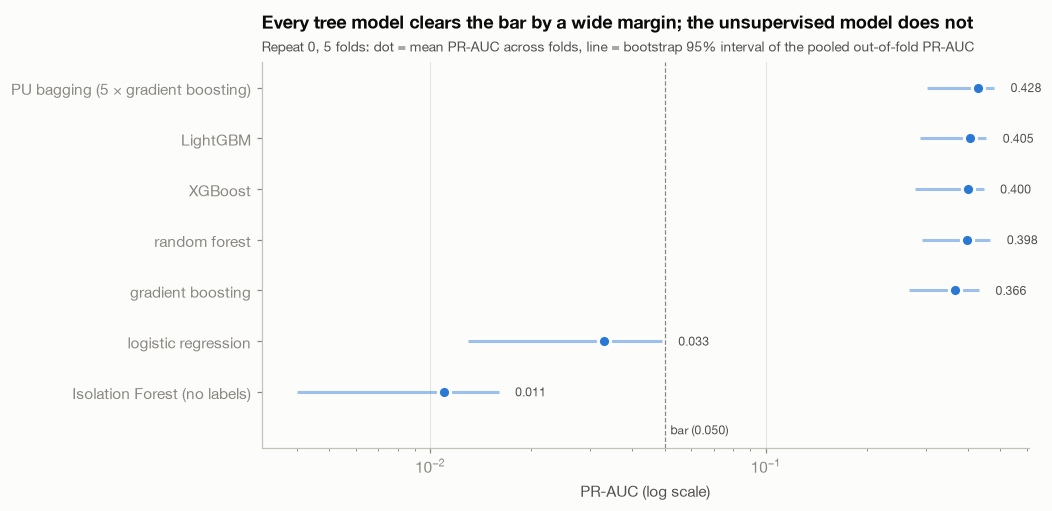

In [8]:
def interval_chart(frame: pl.DataFrame, title: str, note: str) -> None:
    frame = frame.sort("pr_auc")
    _, ax = plt.subplots(figsize=(9, 0.45 * frame.height + 1.4))
    yy = np.arange(frame.height)
    ax.hlines(yy, frame["pooled_low"], frame["pooled_high"], color=BLUE, linewidth=2, alpha=0.45)
    ax.plot(
        frame["pr_auc"],
        yy,
        "o",
        color=BLUE,
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
    )
    ax.axvline(0.050, color=MUTED, linewidth=0.8, linestyle="--")
    ax.text(0.052, -0.75, "bar (0.050)", color=INK_2, fontsize=8, va="center")
    for i, value in enumerate(frame["pr_auc"]):
        ax.text(
            max(frame["pooled_high"][i], value) * 1.12,
            i,
            f"{value:.3f}",
            color=INK_2,
            fontsize=8,
            va="center",
        )
    ax.set_xscale("log")
    ax.set_yticks(yy, frame["experiment"])
    ax.set_ylim(-1.1, frame.height - 0.5)
    ax.set_ylim(-1.1, frame.height - 0.5)
    ax.grid(axis="x")
    ax.set_xlabel("PR-AUC (log scale)")
    ax.set_title(title, pad=22)
    subtitle(ax, note)
    plt.show()


interval_chart(
    families,
    "Every tree model clears the bar by a wide margin; the unsupervised model does not",
    "Repeat 0, 5 folds: dot = mean PR-AUC across folds, line = bootstrap 95% interval of the pooled out-of-fold PR-AUC",
)

**Reading.** All tree models land close together: **PR-AUC 0.37–0.43, 11–13× the logistic regression**
(0.033 on the same folds), with overlapping intervals — the implementation matters much less than moving from a
linear model to trees. PU bagging is the highest on this repeat (0.43) but inside the others' intervals, at about
four times the cost of one model. Isolation Forest, which never sees a label, stays *below* the logistic
regression (0.011): with these features the takeovers are not simply "unusual logins", and a handful of labels
is worth more than none (in line with ADBench, Han et al., 2022).

Most of the gain is on the Romania campaign (PR-AUC 0.02 → ~0.5); the other takeovers improve too (0.01 → ~0.07;
recall at 1%: 58% → 72% for the random forest), but remain the hard part.

## 🧩 3 · New features from the takeover profile

Two new feature groups (`src/data/features.py`, past-only and tested for leakage like the others):

| Group | Columns | Hypothesis |
| --- | --- | --- |
| `campaign` | share of earlier attempts from this ASN / IP that failed or came from an attack IP; attempts and failures from this ASN in the previous 24 full hours; accounts that already used this exact user agent | attackers reuse infrastructure across victims |
| `travel` | country change less than an hour after the previous successful login; countries the user had succeeded from before | impossible travel; a new country means more for a user who never travels |

In [9]:
for name in ["random forest", "LightGBM"]:
    for label, groups_added in [
        ("+ campaign", ("campaign",)),
        ("+ travel", ("travel",)),
        ("+ campaign + travel", ("campaign", "travel")),
    ]:
        run(
            f"{name} {label}",
            candidate(name),
            feature_columns((*DEFAULT_GROUPS, *groups_added)),
            step="new features",
        )
pl.concat(
    [
        families.filter(pl.col("experiment").is_in(["random forest", "LightGBM"])),
        table("new features"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest""",0.398,0.292,0.467,0.778,0.876,0.505,1.0,0.071,0.72,68
"""LightGBM""",0.405,0.288,0.454,0.787,0.867,0.5,1.0,0.058,0.7,44
"""random forest + campaign""",0.394,0.287,0.45,0.813,0.894,0.468,1.0,0.084,0.76,84
"""random forest + travel""",0.419,0.318,0.489,0.787,0.876,0.537,1.0,0.085,0.72,76
"""random forest + campaign + travel""",0.407,0.322,0.491,0.823,0.894,0.526,1.0,0.109,0.76,86
"""LightGBM + campaign""",0.39,0.273,0.436,0.796,0.894,0.479,0.984,0.07,0.78,51
"""LightGBM + travel""",0.43,0.325,0.495,0.787,0.858,0.565,1.0,0.079,0.68,48
"""LightGBM + campaign + travel""",0.416,0.302,0.469,0.796,0.867,0.511,1.0,0.086,0.74,52


**Reading.** With both new groups, the **non-Romania** takeovers gain most: their PR-AUC rises from 0.071 to
0.109 (random forest) and from 0.058 to 0.086 (LightGBM), and their recall at 1% by 4 points; overall PR-AUC moves
little (0.40 → 0.41–0.42). Separately, `travel` raises the overall PR-AUC and `campaign` the non-Romania ranking.
These are single-repeat differences inside the noise, so section 7 re-checks them on all 15 folds with LightGBM on
three feature sets.

## ⚖️ 4 · Campaign balancing

In training, the Romania takeovers outnumber all the others. `selection.campaign_weights` gives the dominant
campaign (the country with the most takeovers in the training sample) and all other takeovers the **same total
weight**; legitimate logins are untouched.

In [10]:
for name in ["random forest", "LightGBM"]:
    run(
        f"{name} + campaign + travel, campaign-balanced",
        candidate(name, balance_campaign=True),
        NEW,
        step="balancing",
    )
pl.concat(
    [
        table("new features").filter(pl.col("experiment").str.ends_with("campaign + travel")),
        table("balancing"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest + campaign + travel""",0.407,0.322,0.491,0.823,0.894,0.526,1.0,0.109,0.76,86
"""LightGBM + campaign + travel""",0.416,0.302,0.469,0.796,0.867,0.511,1.0,0.086,0.74,52
"""random forest + campaign + travel, campaign-balanc…",0.42,0.326,0.496,0.814,0.903,0.507,1.0,0.127,0.78,92
"""LightGBM + campaign + travel, campaign-balanced""",0.414,0.295,0.462,0.805,0.885,0.493,0.984,0.08,0.76,51


**Reading.** For the random forest, balancing helps on both counts: overall PR-AUC 0.407 → 0.420, non-Romania
PR-AUC 0.109 → 0.127, non-Romania recall at 1% 76% → 78%. LightGBM does not benefit (0.416 → 0.414). On all 15
folds (section 7) the balanced forest keeps the edge over the unbalanced one (0.429 vs 0.417; non-Romania 0.137 vs
0.116).

## 🧭 5 · Leave-campaign-out

The strongest test of generalisation available here: **hide one group of takeovers from training** (they are
still scored), and measure how well the model detects them anyway. A model that only memorised the Romania campaign
would fail on it once hidden.

In [11]:
leave_out = []
for name, fitter, columns in [
    ("logistic regression", candidate("logistic regression"), BASE),
    ("random forest + campaign + travel", candidate("random forest"), NEW),
    ("LightGBM + campaign + travel", candidate("LightGBM"), NEW),
]:
    seen = run(f"{name} · nothing hidden", fitter, columns, step="leave-out")
    for hidden_name, hidden in groups.items():
        oof = run(f"{name} · {hidden_name} hidden", fitter, columns, hide=hidden, step="leave-out")
        for status, scores in (("seen in training", seen), ("hidden from training", oof)):
            m = group_metrics(y, scores, {hidden_name: hidden})[hidden_name]
            leave_out.append({"model": name, "takeovers": hidden_name, "status": status, "pr_auc": m["pr_auc"],
                              "recall_0_1pct": m["recall_at_0_1pct"], "recall_1pct": m["recall_at_1pct"]})  # fmt: skip
leave_out = pl.DataFrame(leave_out).with_columns(pl.col(pl.Float64).round(3))
leave_out

model,takeovers,status,pr_auc,recall_0_1pct,recall_1pct
str,str,str,f64,f64,f64
"""logistic regression""","""Romania""","""seen in training""",0.019,0.694,0.984
"""logistic regression""","""Romania""","""hidden from training""",0.008,0.548,0.919
"""logistic regression""","""other""","""seen in training""",0.012,0.32,0.58
"""logistic regression""","""other""","""hidden from training""",0.004,0.28,0.64
"""random forest + campaign + travel""","""Romania""","""seen in training""",0.526,0.984,1.0
"""random forest + campaign + travel""","""Romania""","""hidden from training""",0.239,0.823,0.952
"""random forest + campaign + travel""","""other""","""seen in training""",0.109,0.58,0.76
"""random forest + campaign + travel""","""other""","""hidden from training""",0.009,0.48,0.62
"""LightGBM + campaign + travel""","""Romania""","""seen in training""",0.511,0.968,1.0


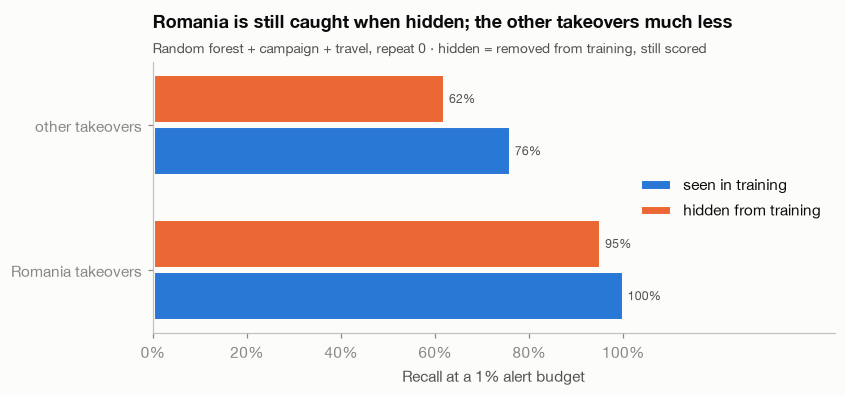

In [12]:
rf = leave_out.filter(pl.col("model").str.starts_with("random forest"))
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = ["Romania", "other"]
for offset, status, color in [
    (-0.18, "seen in training", BLUE),
    (0.18, "hidden from training", ORANGE),
]:
    values = [
        rf.filter((pl.col("takeovers") == g) & (pl.col("status") == status))["recall_1pct"][0]
        for g in labels
    ]
    bars = ax.barh(
        np.arange(2) + offset,
        values,
        height=0.34,
        color=color,
        label=status,
        edgecolor=SURFACE,
        linewidth=2,
    )
    for bar, value in zip(bars, values, strict=True):
        ax.text(
            value + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.0%}",
            va="center",
            fontsize=8,
            color=INK_2,
        )
ax.set_yticks(np.arange(2), [f"{g} takeovers" for g in labels])
ax.set_xlim(0, 1.45)
ax.set_xticks(np.linspace(0, 1, 6), [f"{v:.0%}" for v in np.linspace(0, 1, 6)])
ax.set_xlabel("Recall at a 1% alert budget")
ax.legend(loc="center right")
ax.set_title("Romania is still caught when hidden; the other takeovers much less", pad=22)
subtitle(
    ax, "Random forest + campaign + travel, repeat 0 · hidden = removed from training, still scored"
)
plt.show()

**Reading.** With the Romania campaign **removed from training**, both models still put **95% (random forest)
and 94% (LightGBM) of it in the top 1%**, and 82% / 77% in the top 0.1%. Its PR-AUC halves (0.53 → 0.24), so the
ranking is less sharp, and the campaign is not entirely unseen: its infrastructure still reaches the model through
past-only features computed from all attempts (the attack-IP history of its networks, a user agent already used by
other accounts). What the models learnt transfers because Romania's takeovers share the generic marks of a takeover
— a new country, attack-IP networks (81% of them), a dormant account, rare values.

The reverse is **much weaker**: with the other takeovers hidden, their recall at 1% falls from 76% to 62% (random
forest; LightGBM 74% → 60%) and their PR-AUC from ~0.1 to ~0.01. About half still land in the top 0.1%, but none
near the very top. Only 18% of them come from attack IPs, so they share less with Romania. Detecting a *different*
kind of attack rests on ~50 heterogeneous takeovers: the honest limit of these results.

With Romania hidden, the **non-Romania** PR-AUC doubles (0.11 → 0.22 for the random forest, 0.09 → 0.21 for
LightGBM; `pr_auc_other` below): the campaign drowns out the rest in training, which campaign balancing (section 4)
only partly corrects.

In [13]:
table("leave-out")

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""logistic regression · nothing hidden""",0.033,0.013,0.049,0.528,0.805,0.019,0.984,0.012,0.58,29
"""logistic regression · Romania hidden""",0.016,0.006,0.021,0.437,0.752,0.008,0.919,0.005,0.54,30
"""logistic regression · other hidden""",0.038,0.017,0.049,0.591,0.832,0.033,0.984,0.004,0.64,25
"""random forest + campaign + travel · nothing hidden""",0.407,0.322,0.491,0.823,0.894,0.526,1.0,0.109,0.76,84
"""random forest + campaign + travel · Romania hidden""",0.297,0.207,0.372,0.706,0.867,0.239,0.952,0.219,0.74,80
"""random forest + campaign + travel · other hidden""",0.286,0.187,0.343,0.778,0.831,0.425,1.0,0.009,0.62,60
"""LightGBM + campaign + travel · nothing hidden""",0.416,0.302,0.469,0.796,0.867,0.511,1.0,0.086,0.74,52
"""LightGBM + campaign + travel · Romania hidden""",0.293,0.218,0.381,0.671,0.858,0.248,0.935,0.205,0.74,51
"""LightGBM + campaign + travel · other hidden""",0.334,0.203,0.367,0.76,0.823,0.476,1.0,0.006,0.6,45


## 🔬 6 · Ablations — tested, not assumed

Each feature family that the EDA flagged as weak or suspicious is **added or removed** and measured, on the random
forest with `campaign` + `travel`. Nothing is discarded without this test.

In [14]:
ablations = {
    "+ RTT (round-trip time)": feature_columns((*DEFAULT_GROUPS, "campaign", "travel", "rtt")),
    "+ synthesis artefacts (placeholder ASN / IP flags)": feature_columns(
        (*DEFAULT_GROUPS, "campaign", "travel", "artefacts")
    ),
    "− fine geography (region / city)": [
        c for c in NEW if c not in {"new_region", "new_city", "region_missing", "city_missing"}
    ],
    "− time of day / weekday": [c for c in NEW if c not in {"hour", "weekday"}],
    "− global rarity": [c for c in NEW if not c.startswith("global_share_")],
}
for label, columns in ablations.items():
    run(
        f"random forest + campaign + travel {label}",
        candidate("random forest"),
        columns,
        step="ablations",
    )
pl.concat(
    [
        table("new features").filter(pl.col("experiment") == "random forest + campaign + travel"),
        table("ablations"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest + campaign + travel""",0.407,0.322,0.491,0.823,0.894,0.526,1.0,0.109,0.76,86
"""random forest + campaign + travel + RTT (round-tri…",0.398,0.305,0.474,0.814,0.903,0.505,1.0,0.089,0.78,81
"""random forest + campaign + travel + synthesis arte…",0.411,0.326,0.497,0.823,0.911,0.533,1.0,0.102,0.8,80
"""random forest + campaign + travel − fine geography…",0.41,0.322,0.49,0.805,0.911,0.521,1.0,0.112,0.8,77
"""random forest + campaign + travel − time of day / …",0.42,0.323,0.496,0.831,0.894,0.533,1.0,0.106,0.78,75
"""random forest + campaign + travel − global rarity""",0.241,0.143,0.285,0.725,0.894,0.26,1.0,0.048,0.74,62


**Reading.**

* **RTT adds nothing** (0.407 → 0.398; the synthesis explains why), so it stays out — now with evidence.
* **Synthesis artefacts add nothing beyond noise** (0.411): the model does not need generator quirks, and they stay
  out.
* **Fine geography and time** make no measurable difference either way (0.410 and 0.420, inside the interval
  0.32–0.49); they are kept (no evidence to remove them).
* **Global rarity is essential**: without it PR-AUC falls from 0.407 to 0.241 (−41%). This is the empirical side of
  the issue #5 finding about Freeman's score: on this service, rare values *raise* the risk.

## 🎛️ 7 · Tuning, learning curves and finalists

The two best families after sections 2–6 are the **random forest** and **LightGBM** (gradient boosting; its
scikit-learn and XGBoost versions perform the same). Each gets a small, pre-declared grid on repeat 0 with the
`campaign` + `travel` features. Random forest (with campaign balancing): leaf size and features per split.

In [15]:
def forest(leaf: int, features: str | float):
    def build(columns, seed):
        model = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=leaf,
            max_features=features,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=seed,
        )
        return selection._pipeline(columns, model)

    return build


for leaf, features in [(2, "sqrt"), (10, "sqrt"), (5, 0.5)]:
    selection.SUPERVISED[f"random forest (leaf {leaf}, features {features})"] = forest(
        leaf, features
    )
    run(
        f"random forest (leaf {leaf}, features {features}), balanced",
        candidate(f"random forest (leaf {leaf}, features {features})", balance_campaign=True),
        NEW,
        step="tuning",
    )
pl.concat(
    [
        table("balancing").filter(pl.col("experiment").str.starts_with("random forest")),
        table("tuning"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""random forest + campaign + travel, campaign-balanc…",0.42,0.326,0.496,0.814,0.903,0.507,1.0,0.127,0.78,92
"""random forest (leaf 2, features sqrt), balanced""",0.443,0.346,0.519,0.823,0.902,0.527,0.984,0.147,0.8,90
"""random forest (leaf 10, features sqrt), balanced""",0.403,0.308,0.479,0.796,0.903,0.486,1.0,0.111,0.78,91
"""random forest (leaf 5, features 0.5), balanced""",0.316,0.229,0.387,0.725,0.867,0.371,0.984,0.067,0.72,191


**Reading.** For the random forest, **smaller leaves help** (leaf size 2: 0.443, non-Romania PR-AUC 0.147;
leaf size 10: 0.403), while considering half of the features at each split is clearly worse (0.316) and twice as
slow. For LightGBM, 31 leaves (0.423) is level with the default 15 (0.416), and smaller trees or a faster learning
rate are worse. The forest's leaf-size-2 point joins the finalists; LightGBM keeps its default (the 31-leaf point is
within 0.01 of it).

LightGBM: tree size, learning rate and number of trees (no balancing, which did not help it in section 4).

In [16]:
def boosting(leaves: int, rate: float, trees: int, min_leaf: int):
    def build(columns, seed):
        model = LGBMClassifier(
            n_estimators=trees,
            learning_rate=rate,
            num_leaves=leaves,
            min_child_samples=min_leaf,
            reg_lambda=1.0,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            n_jobs=-1,
            random_state=seed,
            verbose=-1,
        )
        return selection._pipeline(columns, model)

    return build


for leaves, rate, trees, min_leaf in [(7, 0.05, 300, 40), (31, 0.05, 300, 40), (15, 0.1, 150, 20)]:
    name = f"LightGBM (leaves {leaves}, rate {rate}, trees {trees}, min leaf {min_leaf})"
    selection.SUPERVISED[name] = boosting(leaves, rate, trees, min_leaf)
    run(name, candidate(name), NEW, step="tuning LightGBM")
pl.concat(
    [
        table("new features").filter(pl.col("experiment") == "LightGBM + campaign + travel"),
        table("tuning LightGBM"),
    ]
)

experiment,pr_auc,pooled_low,pooled_high,recall_0_1pct,recall_1pct,pr_auc_romania,recall_1pct_romania,pr_auc_other,recall_1pct_other,seconds
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""LightGBM + campaign + travel""",0.416,0.302,0.469,0.796,0.867,0.511,1.0,0.086,0.74,52
"""LightGBM (leaves 7, rate 0.05, trees 300, min leaf…",0.393,0.267,0.431,0.778,0.876,0.456,0.984,0.073,0.74,45
"""LightGBM (leaves 31, rate 0.05, trees 300, min lea…",0.423,0.317,0.486,0.796,0.876,0.53,0.984,0.081,0.74,61
"""LightGBM (leaves 15, rate 0.1, trees 150, min leaf…",0.385,0.281,0.448,0.769,0.903,0.483,0.984,0.074,0.8,40


**Learning curves.** Is the model limited by data (more takeovers would help) or by its capacity, and does it
overfit? The random forest with campaign balancing is trained on a growing random share of the *training users* of
each fold (25% → 100%), and scored on its own training logins and on the held-out fold. Training time is recorded
for the scalability chart.

In [17]:
user_draw = folds.select("user_id").with_columns(
    pl.Series("u", np.random.default_rng(20261103).random(folds.height))
)
u = dev.select("user_id").join(user_draw, on="user_id", how="left")["u"].to_numpy()
CURVE_MODELS = {
    "random forest, balanced": candidate("random forest", balance_campaign=True),
    "LightGBM": candidate("LightGBM"),
}
curve = []
for model_label, fitter in CURVE_MODELS.items():
    for share in (0.25, 0.5, 0.75, 1.0):
        for k in range(N_FOLDS):
            train_mask = (fold[0] != k) & (u < share)
            train = dev.filter(pl.Series(train_mask))
            start = time.perf_counter()
            scorer = fitter(train, NEW)
            seconds = time.perf_counter() - start
            held_out = fold[0] == k
            # "training PR-AUC" scores the whole training fold; only 5% of its legitimate logins
            # (and every takeover) were in the sample the model was fitted on
            curve.append({
                "model": model_label, "share of training users": share, "fold": k,
                "training logins": int(train_mask.sum()), "training takeovers": int(y[train_mask].sum()),
                "fit seconds": seconds,
                "training PR-AUC": evaluate(y[train_mask], scorer(train))["pr_auc"],
                "validation PR-AUC": evaluate(y[held_out], scorer(dev.filter(pl.Series(held_out))))["pr_auc"],
            })  # fmt: skip
curve = pl.DataFrame(curve)
curve_summary = curve.group_by("model", "share of training users", maintain_order=True).agg(
    pl.col("training logins", "training takeovers", "fit seconds").mean().round(1),
    pl.col("training PR-AUC").mean().round(3).alias("training PR-AUC"),
    pl.col("validation PR-AUC").mean().round(3).alias("validation PR-AUC"),
    pl.col("validation PR-AUC").std().round(3).alias("validation std"),
)
curve_summary

model,share of training users,training logins,training takeovers,fit seconds,training PR-AUC,validation PR-AUC,validation std
str,f64,f64,f64,f64,f64,f64,f64
"""random forest, balanced""",0.25,1575048.8,23.2,2.4,0.965,0.259,0.083
"""random forest, balanced""",0.5,3.157328e6,48.0,5.2,0.895,0.375,0.136
"""random forest, balanced""",0.75,4.727132e6,69.6,9.6,0.904,0.434,0.12
"""random forest, balanced""",1.0,6294467.2,89.6,14.2,0.869,0.42,0.132
"""LightGBM""",0.25,1575048.8,23.2,1.5,0.895,0.3,0.106
"""LightGBM""",0.5,3.157328e6,48.0,2.2,0.943,0.411,0.091
"""LightGBM""",0.75,4.727132e6,69.6,3.1,0.847,0.405,0.149
"""LightGBM""",1.0,6294467.2,89.6,3.7,0.774,0.416,0.146


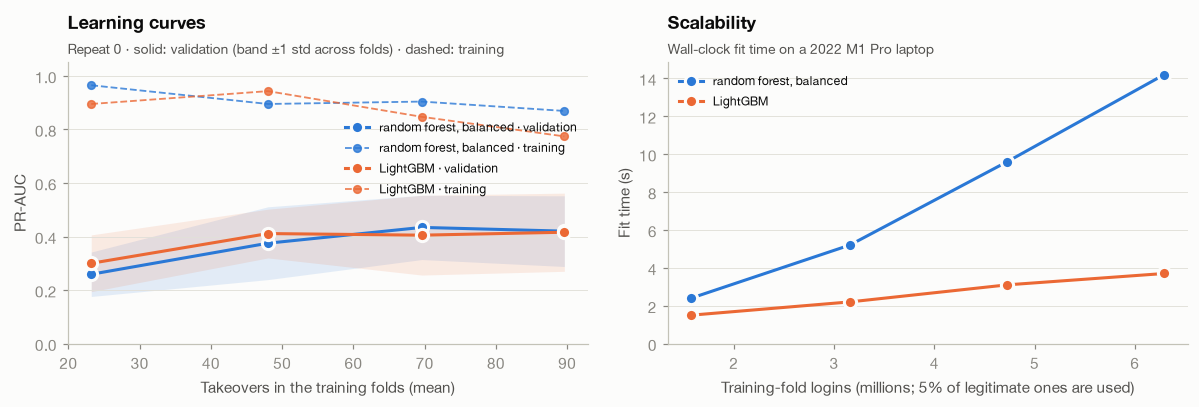

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for model_label, color in zip(CURVE_MODELS, (BLUE, ORANGE), strict=True):
    part = curve_summary.filter(pl.col("model") == model_label)
    x = part["training takeovers"]
    ax1.plot(
        x,
        part["validation PR-AUC"],
        "o-",
        color=color,
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
        label=f"{model_label} · validation",
    )
    ax1.plot(
        x,
        part["training PR-AUC"],
        "o--",
        color=color,
        markersize=5,
        linewidth=1.2,
        alpha=0.8,
        label=f"{model_label} · training",
    )
    ax1.fill_between(
        x,
        part["validation PR-AUC"] - part["validation std"],
        part["validation PR-AUC"] + part["validation std"],
        color=color,
        alpha=0.12,
        linewidth=0,
    )
    ax2.plot(
        part["training logins"] / 1e6,
        part["fit seconds"],
        "o-",
        color=color,
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
        label=model_label,
    )
ax1.set_ylim(0, 1.05)
ax1.set_xlabel("Takeovers in the training folds (mean)")
ax1.set_ylabel("PR-AUC")
ax1.grid(axis="y")
ax1.legend(loc="center right", bbox_to_anchor=(1.0, 0.66), fontsize=8)
ax1.set_title("Learning curves", pad=22)
subtitle(ax1, "Repeat 0 · solid: validation (band ±1 std across folds) · dashed: training")
ax2.set_ylim(0, None)
ax2.set_xlabel("Training-fold logins (millions; 5% of legitimate ones are used)")
ax2.set_ylabel("Fit time (s)")
ax2.grid(axis="y")
ax2.legend(loc="upper left", fontsize=8)
ax2.set_title("Scalability", pad=22)
subtitle(ax2, "Wall-clock fit time on a 2022 M1 Pro laptop")
plt.tight_layout()
plt.show()

**Reading (learning curves).** Validation PR-AUC rises with labels — random forest 0.26 → 0.38 → 0.43 with
~23, ~48 and ~70 training takeovers; LightGBM 0.30 → 0.41 — and then stays level (0.42 with all ~90) within a
fold-to-fold spread of ±0.08–0.15, so the last step is inconclusive rather than a proven plateau. Training PR-AUC is
far higher (0.87–0.97 for the forest, 0.77–0.94 for LightGBM; computed on the whole training fold, of which only
the 5% sampled legitimate logins and the takeovers were used for fitting): **a large variance gap — the models
overfit their ~90 training takeovers.** More regularisation is not the cure: the grid in this section shows that
*larger* leaves or *smaller* trees score lower. The gap comes from having few positives, so more *labels* is what
would help, mostly at the small end. Fit time grows linearly with the data (forest 2 → 14 s, LightGBM 1.5 → 4 s per
training fold).

**Finalists on all 15 folds.** The rule, coded before running (cell below): among the models whose pooled
interval lies above the bar (0.050) and whose recall at 1% is ≥ 0.80, select the **highest mean PR-AUC over the 15
folds**. The best point of the forest's grid joins the finalists (LightGBM keeps its default: its best grid point is within 0.01 of it), and so do LightGBM
with only `travel` and with the issue #4 features, so the choice of feature groups is re-checked on all 15 folds.
A **paired comparison** on the same 15 folds then tells whether a difference between finalists is larger than its
own uncertainty. Caveat: repeat 0 also served the screening decisions above (no nested cross-validation), so the
development estimates are slightly optimistic; the unbiased numbers come from the test side in issue #7.

In [19]:
TUNED_FOREST = "random forest (leaf 2, features sqrt)"  # best point of the forest grid
FINALISTS = {  # label: (fitter, columns, same experiment already run on repeat 0, model, balanced)
    "logistic regression (bar)": (candidate("logistic regression"), BASE, "logistic regression", "logistic regression", False),
    "random forest + campaign + travel, balanced": (
        candidate("random forest", balance_campaign=True), NEW,
        "random forest + campaign + travel, campaign-balanced", "random forest", True,
    ),
    "random forest + campaign + travel": (
        candidate("random forest"), NEW, "random forest + campaign + travel", "random forest", False,
    ),
    "random forest (leaf 2) + campaign + travel, balanced": (
        candidate(TUNED_FOREST, balance_campaign=True), NEW, f"{TUNED_FOREST}, balanced", TUNED_FOREST, True,
    ),
    "LightGBM + campaign + travel": (candidate("LightGBM"), NEW, "LightGBM + campaign + travel", "LightGBM", False),
    "LightGBM + travel": (
        candidate("LightGBM"), feature_columns((*DEFAULT_GROUPS, "travel")), "LightGBM + travel", "LightGBM", False,
    ),
    "LightGBM (issue #4 features)": (candidate("LightGBM"), BASE, "LightGBM", "LightGBM", False),
}  # fmt: skip
for label, (fitter, columns, already_run, _, _) in FINALISTS.items():
    for repeat in range(N_REPEATS):
        run(
            label,
            fitter,
            columns,
            repeat=repeat,
            step="finalists",
            reuse=already_run if repeat == 0 else None,
        )
finalists = (
    pl.DataFrame([r for r in results if r["step"] == "finalists"])
    .group_by("experiment", maintain_order=True)
    .agg(
        pl.col("pr_auc").mean().alias("pr_auc (15 folds)"),
        pl.col("pr_auc_std").mean().alias("std within repeat"),
        pl.col("pr_auc").std().alias("std across repeats"),
        pl.col("recall_0_1pct").mean(),
        pl.col("recall_1pct").mean(),
        pl.col("precision_1pct").mean(),
        pl.col("pr_auc_romania").mean(),
        pl.col("pr_auc_other").mean(),
        pl.col("recall_1pct_romania").mean(),
        pl.col("recall_1pct_other").mean(),
        pl.col("pooled_low").mean(),
        pl.col("pooled_high").mean(),
    )
    .with_columns(pl.col(pl.Float64).round(4))
)
finalists

experiment,pr_auc (15 folds),std within repeat,std across repeats,recall_0_1pct,recall_1pct,precision_1pct,pr_auc_romania,pr_auc_other,recall_1pct_romania,recall_1pct_other,pooled_low,pooled_high
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""logistic regression (bar)""",0.0426,0.0248,0.0086,0.5274,0.8044,0.0011,0.0264,0.0062,0.9677,0.6,0.0117,0.0523
"""random forest + campaign + travel, balanced""",0.4294,0.1425,0.011,0.8185,0.8963,0.0013,0.5282,0.1367,0.9946,0.7733,0.3354,0.5093
"""random forest + campaign + travel""",0.4166,0.1485,0.0131,0.8101,0.8994,0.0013,0.5324,0.116,1.0,0.7733,0.3268,0.5014
"""random forest (leaf 2) + campaign + travel, balanc…",0.4475,0.1419,0.0056,0.8129,0.8902,0.0013,0.5461,0.1588,0.9839,0.7733,0.3547,0.5284
"""LightGBM + campaign + travel""",0.4358,0.1518,0.0171,0.8042,0.8846,0.0013,0.5491,0.1111,0.9892,0.76,0.3369,0.5076
"""LightGBM + travel""",0.4257,0.159,0.008,0.7927,0.8695,0.0012,0.5567,0.068,1.0,0.7133,0.3206,0.4902
"""LightGBM (issue #4 features)""",0.4034,0.1532,0.0093,0.7927,0.8695,0.0012,0.5165,0.0602,0.9946,0.7133,0.2964,0.4635


In [20]:
BAR, MIN_RECALL_1PCT = 0.050, 0.80  # issue #5: upper end of the baseline interval; its recall at 1%
chosen = finalists.filter(
    (pl.col("pooled_low") > BAR) & (pl.col("recall_1pct") >= MIN_RECALL_1PCT)
).sort("pr_auc (15 folds)", descending=True)
best = chosen["experiment"][0]
print("selected:", best)
chosen.select("experiment", "pr_auc (15 folds)", "pr_auc_other", "recall_1pct", "recall_1pct_other")


def per_fold(label: str) -> np.ndarray:
    rows = sorted(
        (r for r in results if r["step"] == "finalists" and r["experiment"] == label),
        key=lambda r: r["repeat"],
    )
    return np.concatenate([r["pr_auc_per_fold"] for r in rows])


best_folds = per_fold(best)
paired = pl.DataFrame(
    [
        {
            "finalist": label,
            "mean difference vs selected": float(np.mean(per_fold(label) - best_folds)),
            "std of the difference": float(np.std(per_fold(label) - best_folds, ddof=1)),
            "folds where the selected model is better": int((best_folds > per_fold(label)).sum()),
        }
        for label in chosen["experiment"]
        if label != best
    ]
).with_columns(pl.col(pl.Float64).round(4))
print("Paired comparison on the same 15 folds (difference = finalist - selected):")
paired

selected: random forest (leaf 2) + campaign + travel, balanced
Paired comparison on the same 15 folds (difference = finalist - selected):


finalist,mean difference vs selected,std of the difference,folds where the selected model is better
str,f64,f64,i64
"""LightGBM + campaign + travel""",-0.0117,0.0453,7
"""random forest + campaign + travel, balanced""",-0.0181,0.0225,14
"""LightGBM + travel""",-0.0218,0.0572,11
"""random forest + campaign + travel""",-0.0309,0.033,13
"""LightGBM (issue #4 features)""",-0.0441,0.0567,13


**Reading (selection).** The selected model is the **random forest with leaf size 2, the `campaign` and
`travel` features and campaign balancing**: mean PR-AUC **0.448** over the 15 folds (~10× the logistic
regression's 0.043), recall 81% at a 0.1% budget and 89% at 1%, precision 0.13% at 1% (about one real takeover per
770 alerts). It also ranks the **non-Romania takeovers best of all finalists** (PR-AUC 0.159 vs 0.11–0.14).

The paired comparison separates real differences from noise:

* against **LightGBM with the same features** it is a **tie** (−0.012 ± 0.045; the selected model is better on only 7
  of 15 folds);
* against the **default forest**, balanced (−0.018 ± 0.023, better on 14 of 15) and unbalanced (13 of 15), the gain
  from **tuning** and from balancing is consistent;
* against **LightGBM on the issue #4 features** (−0.044 ± 0.057, better on 13 of 15) and with `travel` only (11 of
  15), the **new feature groups** pay off.

The model file is 9.8 MB and refits in 19 s on the whole development side. Repeat 0 also served the screening
decisions above (no nested cross-validation), so these development numbers are slightly optimistic.

## 💾 Train the selected model and save it

The selected configuration is refitted on the **whole development side** and saved as a `.joblib` pipeline
(preprocessing + model) in `data/06_models/` (gitignored), with a metadata file. Its out-of-fold development scores
(repeat 0) are saved in `data/07_model_output/`: issue #7 chooses alert thresholds on them, so the test side is
used only once, for the final measurement.

In [21]:
_, columns, _, model_name, balanced = FINALISTS[best]
start = time.perf_counter()
pipeline = train_supervised(model_name, dev, columns, balance_campaign=balanced)
print(
    f"refitted on {dev.height:,} logins ({int(y.sum())} takeovers) in {time.perf_counter() - start:.0f} s"
)

models_dir, output_dir = data_dir / "06_models", data_dir / "07_model_output"
models_dir.mkdir(exist_ok=True)
output_dir.mkdir(exist_ok=True)
model_path = models_dir / f"{config.name}_model.joblib"
joblib.dump(pipeline, model_path)
model_bytes = model_path.read_bytes()
summary = finalists.filter(pl.col("experiment") == best).row(0, named=True)
metadata = {
    "dataset": config.name, "selected": best, "model": model_name, "campaign_balanced": balanced,
    "columns": columns, "negative_share": NEGATIVE_SHARE, "trained_on": "development side (80% of users)",
    "joblib_sha256": hashlib.sha256(model_bytes).hexdigest(), "joblib_megabytes": round(len(model_bytes) / 1e6, 2),
    "cv_15_folds": {k: v for k, v in summary.items() if k != "experiment"},
}  # fmt: skip
(models_dir / f"{config.name}_model.json").write_text(json.dumps(metadata, indent=2))
pl.DataFrame({"event_id": dev["event_id"], "score": oof_cache[f"{best} · repeat 0"]}).write_parquet(
    output_dir / f"{config.name}_dev_oof.parquet"
)
print(f"model file: {len(model_bytes) / 1e6:.2f} MB · sha256 {metadata['joblib_sha256'][:16]}…")
print(
    "saved:",
    *(p.relative_to(REPO_ROOT) for p in sorted(models_dir.glob(f"{config.name}_model.*"))),
    sep="\n  ",
)

refitted on 7,868,084 logins (112 takeovers) in 19 s
model file: 9.79 MB · sha256 26625b4626b200cb…
saved:
  data/06_models/rba_model.joblib
  data/06_models/rba_model.json


## ✅ Conclusions

* **Trees beat the bar by an order of magnitude.** Every tree-based family reaches PR-AUC ≈ 0.4 on the development
  folds against 0.03–0.04 for the logistic regression; the implementation (random forest, scikit-learn boosting,
  LightGBM, XGBoost) matters much less than the move away from a linear model. **Selected: random forest (leaf size 2)
  + `campaign` + `travel`, campaign-balanced**, PR-AUC 0.448 on 15 folds, recall 89% at a 1% budget, tied with
  LightGBM on the same features and best on the non-Romania takeovers.
* **Labels beat no labels.** Isolation Forest without labels stays below even the logistic regression; the ~100
  confirmed takeovers carry most of the information. PU bagging adds cost for at most a small, non-significant gain.
* **One campaign is most of the labels.** Hidden from training, it is still caught (95% at 1%), helped by the
  generic marks of a takeover and by infrastructure signals computed from all attempts; the other, heterogeneous
  takeovers generalise much less (hidden, their PR-AUC falls to ~0.01). Balancing the campaign helps the rest only
  partly.
* **The useful signals are behavioural and global**: global rarity (essential: −41% without it), attacker
  infrastructure, novelty for the user and dormancy. RTT and the synthesis artefacts add nothing, as their origin
  predicts.
* **Learning curves**: the models overfit their few training takeovers (large train–validation gap); validation
  improves with more labels up to ~50–70 takeovers, and more regularisation does not help.
* **The weak spot** is the non-Romania takeovers: about 3 in 4 are caught at a 1% budget, with low precision.
  Issue #7 measures the selected model on the test side, chooses thresholds on the development scores saved above,
  and analyses the errors.

Numbers in this notebook are development-side, out-of-fold estimates; the unbiased numbers come from the test side in
issue #7.